#  Comprehensive Solar Energetic Electron event Catalogue (CoSEE-Cat), Data Release 1
This notebook is set up to analyse the CoSEE-Cat DR1 dataset (see Warmuth 2025).

This notebook reads in the CoSEE-cat .csv, and finds the solar energetic electron events that are not associated with a STIX X-ray flare. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

path = Path(r"C:\Users\pauls\SEPs\coseecat_dr1\data\CoSEE_full.csv")
print(path.exists(), f"{path.stat().st_size / 1e6:.2f} MB")

True 0.13 MB


In [2]:
# look at the raw text file first

with open(path, "r", encoding="utf-8", errors="replace") as f:
    for i, line in enumerate(f):
        print(i, line[:300].rstrip())
        if i >= 15:
            break
        

0 event_id,event_date,solo_dist,solo_lon,solo_lat,epd_tonset,epd_delta_t,epd_tpeak,epd_ipeak,epd_epeak,tsa_itime,vda_itime,vda_time_unc,vda_lpath,vda_path_unc,nominal_path,epd_aniso,epd_compo,epd_series,epd_dispersive,goes_class,goes_estim,stix_status,stix_tpeak,stix_emax,stix_tpeak_epd,stix_tpeak_rpw
1 2011170942,2020-11-17,0.928,122.2,-6.0,2020-11-17T09:42:30,60,2020-11-17T10:21:30,3.42E+04,43,2020-11-17T09:27:27,,,,,1.06,large,impulsive,Y,,,C1,1,2020-11-17T09:32:45,25.0,2020-11-17T09:26:49,,929.0,-285,-18.1,-167.1,340.6,12786,2,1,969.0,-317.0,-18.8,-156.3,351.4,12786,flare,510.0,628.0,32.4,157.8
2 2011171841,2020-11-17,0.926,122.1,-6.0,2020-11-17T18:41:30,60,2020-11-17T18:48:30,2.70E+04,43,2020-11-17T18:26:29,2020-11-17T18:25:24,0.9,1.15,0.03,1.06,large,impulsive,Y,Y,,B6,1,2020-11-17T18:26:57,15.0,2020-11-17T18:26:57,2020-11-17T18:26:57,949.0,-383,-22.6,-154.9,347.9,12786,1,1,983.0,-267.0,-16
3 2011181056,2020-11-18,0.924,122.1,-6.0,2020-11-18T10:56:30,60,,,24,2020-11-18T10:34:33,,,

In [3]:
# Read in the file

df = pd.read_csv(path)
# If Cell 2 shows comment lines, use:  pd.read_csv(path, comment="#")
# If it shows fill values such as -9999: pd.read_csv(path, na_values=[-9999, "-9999"])

print(df.shape)
df.head()

(303, 99)


,event_id,event_date,solo_dist,solo_lon,solo_lat,epd_tonset,epd_delta_t,epd_tpeak,epd_ipeak,epd_epeak,...,ss_fr_delay,sw_condition,mag_polarity,ip_complex,ip_confidence,conn_carr_lon,conn_lon_unc,conn_hgs_lat,conn_lat_unc,conn_conf
0,2011170942,2020-11-17,0.928,122.2,-6.0,2020-11-17T09:42:30,60,2020-11-17T10:21:30,34200.0,43.0,...,30.0,NaN,NaN,n,2,333.28,4.00,-30.77,5.75,3
1,2011171841,2020-11-17,0.926,122.1,-6.0,2020-11-17T18:41:30,60,2020-11-17T18:48:30,27000.0,43.0,...,20.0,NaN,NaN,n,2,332.29,6.50,-31.22,9.25,3
2,2011181056,2020-11-18,0.924,122.1,-6.0,2020-11-18T10:56:30,60,NaN,NaN,24.0,...,4.0,NaN,NaN,y,2,329.34,3.16,-31.16,3.41,3
3,2011181214,2020-11-18,0.924,122.1,-6.0,2020-11-18T12:14:30,60,2020-11-18T12:15:30,2900.0,43.0,...,3.0,NaN,NaN,y,2,329.34,3.16,-31.16,3.41,3
4,2011181331,2020-11-18,0.924,122.1,-6.0,2020-11-18T13:31:30,60,2020-11-18T13:41:30,7640.0,43.0,...,2.0,NaN,NaN,y,2,329.34,3.16,-31.16,3.41,3


In [4]:
# Structure overview
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 99 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   event_id           303 non-null    int64  
 1   event_date         303 non-null    str    
 2   solo_dist          303 non-null    float64
 3   solo_lon           303 non-null    float64
 4   solo_lat           303 non-null    float64
 5   epd_tonset         303 non-null    str    
 6   epd_delta_t        303 non-null    int64  
 7   epd_tpeak          300 non-null    str    
 8   epd_ipeak          300 non-null    float64
 9   epd_epeak          303 non-null    float64
 10  tsa_itime          303 non-null    str    
 11  vda_itime          126 non-null    str    
 12  vda_time_unc       126 non-null    float64
 13  vda_lpath          126 non-null    float64
 14  vda_path_unc       126 non-null    float64
 15  nominal_path       303 non-null    float64
 16  epd_aniso          226 non-null    st

In [5]:
# Columns and missing data

summary = pd.DataFrame({
    "dtype": df.dtypes,
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
summary

,dtype,n_missing,pct_missing,n_unique
event_id,int64,0,0.0,303
event_date,str,0,0.0,149
solo_dist,float64,0,0.0,210
solo_lon,float64,0,0.0,197
solo_lat,float64,0,0.0,97
...,...,...,...,...
conn_carr_lon,float64,0,0.0,206
conn_lon_unc,float64,0,0.0,116
conn_hgs_lat,float64,0,0.0,199
conn_lat_unc,float64,0,0.0,129


In [6]:
# check stix_status

df["stix_status"].value_counts().sort_index()

stix_status
0     15
1    288
Name: count, dtype: int64

In [7]:
def stix_category(r):
    if pd.isna(r["stix_tpeak"]):
        return "no flare time (a or b)"
    if pd.isna(r["stix_hgs_lat"]):
        return "c) flare, no position"
    return "flare + position"

df["stix_cat"] = df.apply(stix_category, axis=1)
pd.crosstab(df["stix_cat"], df["stix_status"], margins=True)

stix_status,0,1,All
stix_cat,,,
"c) flare, no position",0,63,63
flare + position,0,205,205
no flare time (a or b),15,20,35
All,15,288,303


In [8]:
cols = ["event_id", "event_date", "stix_status", "stix_tpeak", "stix_emax",
        "goes_estim", "stix_epd_qual", "eui_status", "rpw_status"]
df.loc[df["stix_cat"] == "no flare time (a or b)", cols].sort_values("stix_status")

,event_id,event_date,stix_status,stix_tpeak,stix_emax,goes_estim,stix_epd_qual,eui_status,rpw_status
8,2011240701,2020-11-24,0,NaN,NaN,NaN,3,0,1
9,2011241331,2020-11-24,0,NaN,NaN,NaN,3,0,1
10,2011241735,2020-11-24,0,NaN,NaN,NaN,3,0,1
11,2011291337,2020-11-29,0,NaN,NaN,NaN,3,0,1
13,2012100809,2020-12-10,0,NaN,NaN,NaN,3,0,1
12,2012100748,2020-12-10,0,NaN,NaN,NaN,3,0,1
14,2012101344,2020-12-10,0,NaN,NaN,NaN,3,0,1
15,2012102049,2020-12-10,0,NaN,NaN,NaN,3,0,1
19,2012130951,2020-12-13,0,NaN,NaN,NaN,3,0,1
16,2012102346,2020-12-10,0,NaN,NaN,NaN,3,0,1


In [9]:
cols = ["event_id", "event_date", "stix_status", "stix_epd_qual",
        "stix_tpeak_epd", "stix_emax", "goes_estim", "eui_status", "rpw_status"]
no_flare = df[df["stix_cat"] == "no flare time (a or b)"]
no_flare[cols].sort_values(["stix_status", "event_date"])

,event_id,event_date,stix_status,stix_epd_qual,stix_tpeak_epd,stix_emax,goes_estim,eui_status,rpw_status
8,2011240701,2020-11-24,0,3,NaN,NaN,NaN,0,1
9,2011241331,2020-11-24,0,3,NaN,NaN,NaN,0,1
10,2011241735,2020-11-24,0,3,NaN,NaN,NaN,0,1
11,2011291337,2020-11-29,0,3,NaN,NaN,NaN,0,1
12,2012100748,2020-12-10,0,3,NaN,NaN,NaN,0,1
13,2012100809,2020-12-10,0,3,NaN,NaN,NaN,0,1
14,2012101344,2020-12-10,0,3,NaN,NaN,NaN,0,1
15,2012102049,2020-12-10,0,3,NaN,NaN,NaN,0,1
16,2012102346,2020-12-10,0,3,NaN,NaN,NaN,0,1
17,2012111055,2020-12-11,0,3,NaN,NaN,NaN,0,1


In [10]:
pd.crosstab(no_flare["stix_status"], no_flare["stix_epd_qual"])

stix_epd_qual,3
stix_status,
0,15
1,20


In [11]:
for status, dates in no_flare.groupby("stix_status")["event_date"]:
    print(f"\nstix_status = {status} ({len(dates)} events)")
    print(sorted(dates.tolist()))


stix_status = 0 (15 events)
['2020-11-24', '2020-11-24', '2020-11-24', '2020-11-29', '2020-12-10', '2020-12-10', '2020-12-10', '2020-12-10', '2020-12-10', '2020-12-11', '2020-12-11', '2020-12-13', '2021-04-19', '2022-04-28', '2022-04-28']

stix_status = 1 (20 events)
['2020-11-20', '2021-02-14', '2021-05-24', '2021-05-24', '2021-05-24', '2021-05-28', '2021-07-16', '2021-07-18', '2021-12-04', '2021-12-05', '2022-03-18', '2022-03-19', '2022-05-03', '2022-10-18', '2022-10-29', '2022-10-29', '2022-10-29', '2022-10-30', '2022-12-24', '2022-12-24']


In [12]:
pd.crosstab(df["stix_cat"], df["stix_epd_qual"], margins=True)

stix_epd_qual,1,2,3,All
stix_cat,,,,
"c) flare, no position",43,16,4,63
flare + position,96,104,5,205
no flare time (a or b),0,0,35,35
All,139,120,44,303


In [13]:
# Catalague also uses EUI for flare location. 

needs = df[df["stix_hgs_lat"].isna()].copy()
print(len(needs))

needs["has_eui"] = needs["eui_hgs_lat1"].notna()
pd.crosstab(needs["stix_cat"], needs["has_eui"], margins=True)

98


has_eui,False,True,All
stix_cat,,,
"c) flare, no position",21,42,63
no flare time (a or b),22,13,35
All,43,55,98


In [14]:
# Do STIX and EUI agree where both exist? Stonyhurst coordinates

both = df[df["stix_hgs_lat"].notna() & df["eui_hgs_lat1"].notna()]
print(len(both))
print((both["eui_hgs_lon1"] - both["stix_hgs_lon"]).describe())
print((both["eui_hgs_lat1"] - both["stix_hgs_lat"]).describe())

130
count    130.000000
mean       1.246923
std       34.228120
min     -103.400000
25%       -2.200000
50%       -0.200000
75%        0.975000
max      351.200000
dtype: float64
count    130.000000
mean       0.650000
std        9.127021
min      -45.700000
25%       -0.600000
50%        0.400000
75%        1.700000
max       49.700000
dtype: float64


In [15]:
df["eui_type1"].value_counts(dropna=False)

eui_type1
NaN                                                  109
flare                                                 88
flare, jet                                            59
flare, erupting filament                              11
flare, loop opening                                    9
flare, fan-like eruption                               9
erupting filament                                      2
flare, loop-like eruption                              2
flare, loop-like eruption, fan-like eruption           2
flare, jet, loop opening                               2
flare,  loop opening                                   1
loop opening                                           1
jet                                                    1
flare, erupting filament, loop-like eruption           1
flare, loop-like eruption                              1
flare, loop opening, fan-like eruption                 1
flare, loop-opening                                    1
flare, loop-like     

In [16]:
# Do STIX and EUI agree where both exist? Carrington coordinates

stix_col = "stix_carr_lon"   # whatever the real names are
eui_col = "eui_carr_lon1"

both = df[df[stix_col].notna() & df[eui_col].notna()].copy()
print(len(both))

dlon = both[eui_col] - both[stix_col]
dlon = (dlon + 180) % 360 - 180   # wrap into [-180, 180)
print(dlon.describe())

130
count    130.000000
mean      -1.793846
std       14.675586
min     -103.600000
25%       -2.500000
50%       -0.400000
75%        0.700000
max       80.100000
dtype: float64


9 events with |dlon| > 10 deg
5 events with |dlon| > 30 deg
median: -0.4000000000000057  robust sigma: 2.2980300000000167
     stix_carr_lon  eui_carr_lon1   dlon
225          167.0           63.4 -103.6
101          326.1           46.2   80.1
219          131.6           63.5  -68.1
105          302.5          250.1  -52.4
106          336.8           18.9   42.1
193          106.0           87.9  -18.1
166          322.2          309.5  -12.7
0            340.6          351.4   10.8
128          112.6          102.0  -10.6
120          114.2          105.2   -9.0
182          294.2          302.7    8.5
189          108.0           99.7   -8.3
2            343.5          336.2   -7.3
117           84.0           76.7   -7.3
125          114.5          107.3   -7.2


<Axes: >

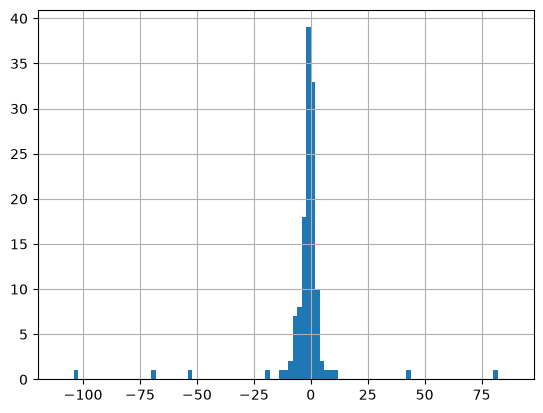

In [18]:
# look at the outliers

both = both.assign(dlon=dlon)

print((dlon.abs() > 10).sum(), "events with |dlon| > 10 deg")
print((dlon.abs() > 30).sum(), "events with |dlon| > 30 deg")

# robust scatter (MAD scaled to be comparable to a Gaussian sigma)
mad = (dlon - dlon.median()).abs().median() * 1.4826
print("median:", dlon.median(), " robust sigma:", mad)

# inspect the worst cases
cols = ["stix_carr_lon", "eui_carr_lon1", "dlon"]  # add date/ID columns here
print(both.loc[dlon.abs().sort_values(ascending=False).index[:15], cols])

dlon.hist(bins=np.arange(-110, 90, 2))

In [19]:
# Look at statistics excluding 6 outliers

core = dlon[(dlon > -13) & (dlon < 11)]   # or: dlon.drop(outlier_index)
print(len(core))
print(core.describe())

124
count    124.000000
mean      -0.912903
std        3.452016
min      -12.700000
25%       -2.400000
50%       -0.400000
75%        0.700000
max       10.800000
dtype: float64


In [20]:
# print a list of all 6 outliers

out = both[(dlon < -13) | (dlon > 11)]
print(out[["stix_carr_lon", "eui_carr_lon1", "dlon"]])   # plus date/ID, flags, eui_carr_lon2 etc.

     stix_carr_lon  eui_carr_lon1   dlon
101          326.1           46.2   80.1
105          302.5          250.1  -52.4
106          336.8           18.9   42.1
193          106.0           87.9  -18.1
219          131.6           63.5  -68.1
225          167.0           63.4 -103.6


In [21]:
# df containing event ID and date, and STIX and EUI longitudes in Carrington coords, and the difference in long between STIX and EUI
both = both.assign(dlon=dlon)

cols = ["event_id", "event_date",
        "stix_carr_lon", "eui_carr_lon1", "eui_carr_lon2", "eui_carr_lon3", "dlon"]

outliers = both.loc[(both["dlon"] < -13) | (both["dlon"] > 11), cols].copy()

# offsets for the second and third EUI positions, wrapped into [-180, 180)
for n in (2, 3):
    d = outliers[f"eui_carr_lon{n}"] - outliers["stix_carr_lon"]
    outliers[f"dlon{n}"] = (d + 180) % 360 - 180

print(len(outliers))   # should be 6
print(outliers)

6
       event_id  event_date  stix_carr_lon  eui_carr_lon1  eui_carr_lon2  eui_carr_lon3   dlon  dlon2  dlon3
101  2203060804  2022-03-06          326.1           46.2            NaN            NaN   80.1    NaN    NaN
105  2203091432  2022-03-09          302.5          250.1            7.2            NaN  -52.4   64.7    NaN
106  2203091559  2022-03-09          336.8           18.9            NaN            NaN   42.1    NaN    NaN
193  2209230459  2022-09-23          106.0           87.9            NaN            NaN  -18.1    NaN    NaN
219  2210290731  2022-10-29          131.6           63.5            NaN            NaN  -68.1    NaN    NaN
225  2210291912  2022-10-29          167.0           63.4            NaN            NaN -103.6    NaN    NaN


In [22]:
# Now look at the 43 events that dont have STIX or EUI
# columns that might hold any kind of position
pos_cols = [c for c in df.columns
            if any(k in c.lower() for k in ["lon", "lat", "carr", "hgs", "hpc", "loc", "pos", "region", "ar", "noaa"])]
print(pos_cols)

['solo_lon', 'solo_lat', 'stix_hpc_x', 'stix_hpc_y', 'stix_hgs_lat', 'stix_hgs_lon', 'stix_carr_lon', 'stix_ar_num', 'eui_hpc_x1', 'eui_hpc_y1', 'eui_hgs_lat1', 'eui_hgs_lon1', 'eui_carr_lon1', 'eui_ar_num1', 'eui_hpc_x2', 'eui_hpc_y2', 'eui_hgs_lat2', 'eui_hgs_lon2', 'eui_carr_lon2', 'eui_ar_num2', 'eui_hpc_x3', 'eui_hpc_y3', 'eui_hgs_lat3', 'eui_hgs_lon3', 'eui_carr_lon3', 'eui_ar_num3', 'metis_tstart1', 'metis_tstart2', 'solohi_tstart', 'post_icme_delay', 'sir_rar_delay', 'mag_polarity', 'conn_carr_lon', 'conn_lon_unc', 'conn_hgs_lat', 'conn_lat_unc']


In [23]:
# events with no STIX and no EUI Carrington longitude
no_pos = df[df["stix_carr_lon"].isna() & df["eui_carr_lon1"].isna()].copy()
print(len(no_pos))   # should be 43

# consistency check: do any of them have STIX/EUI positions in other columns?
check_cols = ["stix_hgs_lon", "stix_hgs_lat", "eui_hgs_lon1", "eui_hgs_lat1"]
print(no_pos[check_cols].notna().sum())

# how many have any position-like value in the other columns you found?
print(no_pos[pos_cols].notna().sum().sort_values(ascending=False))

43
stix_hgs_lon    0
stix_hgs_lat    0
eui_hgs_lon1    0
eui_hgs_lat1    0
dtype: int64
solo_lon           43
solo_lat           43
conn_hgs_lat       43
conn_lat_unc       43
conn_lon_unc       43
conn_carr_lon      43
mag_polarity       28
eui_ar_num1         5
metis_tstart1       5
sir_rar_delay       4
post_icme_delay     1
stix_hpc_x          0
stix_hpc_y          0
stix_hgs_lat        0
stix_carr_lon       0
stix_hgs_lon        0
eui_hpc_x1          0
eui_hpc_y1          0
eui_hgs_lat1        0
stix_ar_num         0
eui_ar_num2         0
eui_carr_lon2       0
eui_hgs_lon2        0
eui_hgs_lat2        0
eui_hpc_y2          0
eui_hpc_x2          0
eui_carr_lon1       0
eui_hgs_lon1        0
metis_tstart2       0
eui_ar_num3         0
eui_carr_lon3       0
eui_hgs_lon3        0
eui_hpc_y3          0
eui_hgs_lat3        0
eui_hpc_x3          0
solohi_tstart       0
dtype: int64


In [24]:
# compare simple properties: replace with the real column names
props = ["event_date", "goes_class", "solo_dist"]   # whatever exists
for p in props:
    print(p)
    print("no position:", no_pos[p].describe())
    print("has position:", df.drop(no_pos.index)[p].describe())

event_date
no position: count             43
unique            31
top       2020-12-10
freq               5
Name: event_date, dtype: object
has position: count            260
unique           129
top       2022-10-29
freq              17
Name: event_date, dtype: object
goes_class
no position: count        3
unique       2
top       B1.8
freq         2
Name: goes_class, dtype: object
has position: count       94
unique      63
top       C2.2
freq         4
Name: goes_class, dtype: object
solo_dist
no position: count    43.000000
mean      0.794512
std       0.176460
min       0.326000
25%       0.730000
50%       0.854000
75%       0.925000
max       1.010000
Name: solo_dist, dtype: float64
has position: count    260.000000
mean       0.685173
std        0.211011
min        0.313000
25%        0.479250
50%        0.649000
75%        0.901750
max        1.015000
Name: solo_dist, dtype: float64


In [25]:
def wrap(x):
    return (x + 180) % 360 - 180

sub = df[df["stix_hgs_lon"].notna()].copy()
sub["flare_rel"] = wrap(sub["stix_hgs_lon"] - sub["solo_lon"])
print(sub["flare_rel"].abs().describe())
print((sub["flare_rel"].abs() > 90).sum(), "events beyond 90 deg")

count    205.000000
mean      53.337073
std       25.885002
min        0.700000
25%       34.200000
50%       52.000000
75%       77.300000
max       89.700000
Name: flare_rel, dtype: float64
0 events beyond 90 deg
